# Assignment 1: Training Simple Neural Networks
Name:   ZENZ Sebastian\
MatNr:  01031159

For this assignment PyTorch is used to train a neural network for a regression task on California Housing Dataset with the goal of predicting the housing value based on verious preductive variables. In part (d) the problem is re-formulated as a binary classification problem.

## 1. Imports and reproducibility

Set seeds so repeated runs are more comparable. `DEVICE` uses a GPU if PyTorch can access one; otherwise, computation runs on the CPU.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

import random
# rng seed
SEED = 302          # random_state=302 was used in assignment sheet, so we use it here as well
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# from housing dataset
FEATURE_NAMES = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude",
]

# use gpu if compatible/available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    print("GPU used:", torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
GPU used: NVIDIA GeForce RTX 4080 SUPER


In [119]:
# save plots for report (snippet from MLAIE)
import os
PLOT_DIR = os.path.join(os.path.dirname(os.path.abspath(__file__)), "plots")

def _save(fig, filename):
    os.makedirs(PLOT_DIR, exist_ok=True)
    path = os.path.join(PLOT_DIR, filename)
    fig.savefig(path, bbox_inches="tight")
    plt.close(fig)
    print(f"Saved plot to {path}")

NameError: name '__file__' is not defined

## 2. Load and inspect the data

The scikit provided split reserves 25% of the data for final testing. Do not use that test split to choose a model or hyperparameters.\
X is storing the features, y is storing the target values (value of house in $100k)

In [103]:
def load_data():
    # import query from assignment sheet
    X, y = fetch_california_housing(return_X_y=True)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=SEED
    )
    return X_train, X_test, y_train, y_test


X_train, X_test, y_train, y_test = load_data()
print(f"Training features: {X_train.shape}; training targets: {y_train.shape}")
print(f"Test features: {X_test.shape}; test targets: {y_test.shape}")
pd.DataFrame(X_train, columns=FEATURE_NAMES).head(6)

Training features: (15480, 8); training targets: (15480,)
Test features: (5160, 8); test targets: (5160,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,3.3409,32.0,3.254902,1.009804,177.0,1.735294,33.90,-118.37
1,4.0000,35.0,4.938095,0.985714,552.0,2.628571,37.71,-122.12
2,4.1997,17.0,5.732759,1.060345,2866.0,3.088362,38.66,-121.76
3,5.6163,27.0,6.515670,1.005698,1140.0,3.247863,33.83,-117.87
4,1.6559,48.0,5.161663,1.000000,1363.0,3.147806,33.99,-118.31
5,2.3023,37.0,4.926952,1.012594,1265.0,3.186398,37.74,-120.93


## 3. Explore the training features

Analyse the target and feature distribution of the training set. Histograms are used to visualize data

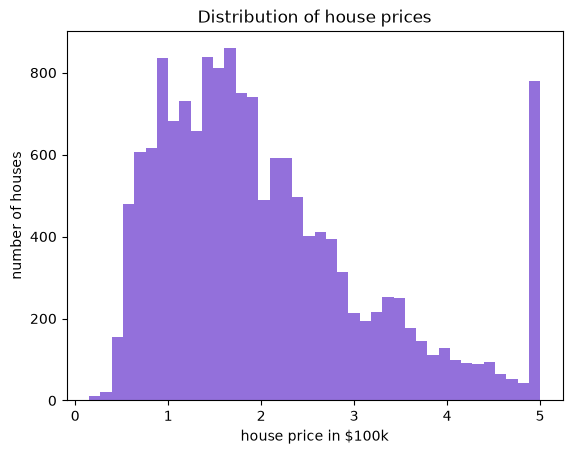

,medHouseVal
count,15480.000000
mean,2.068206
std,1.156928
min,0.149990
25%,1.189000
50%,1.798000
75%,2.647000
max,5.000010


In [104]:
# targets
plt.hist(y_train, bins=40, color="mediumpurple")
plt.xlabel("house price in $100k")
plt.ylabel("number of houses")
plt.title("Distribution of house prices")
plt.show()

frame = pd.DataFrame({"medHouseVal": y_train})
frame.describe()

*Note: there are a few sever outlier (e.g. avg rooms ~5.4, max rooms ~142). To get a good visualization of the distrubition (excluding those severe outliers), another set of plots with a 1-99% percentile slice of the data representation (without changing the original dataset!) is also plotted and included in the report.*

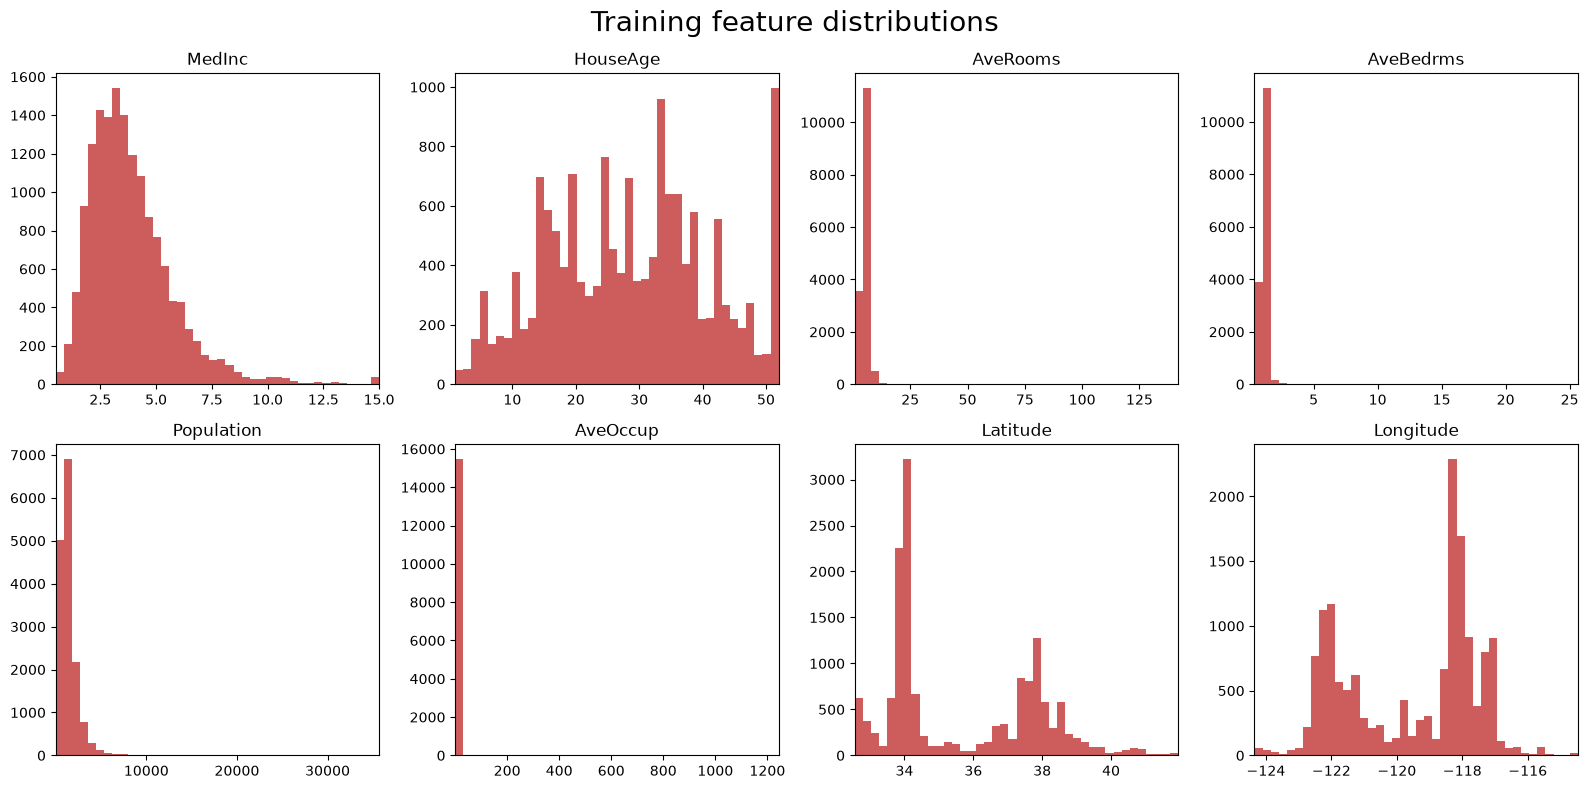

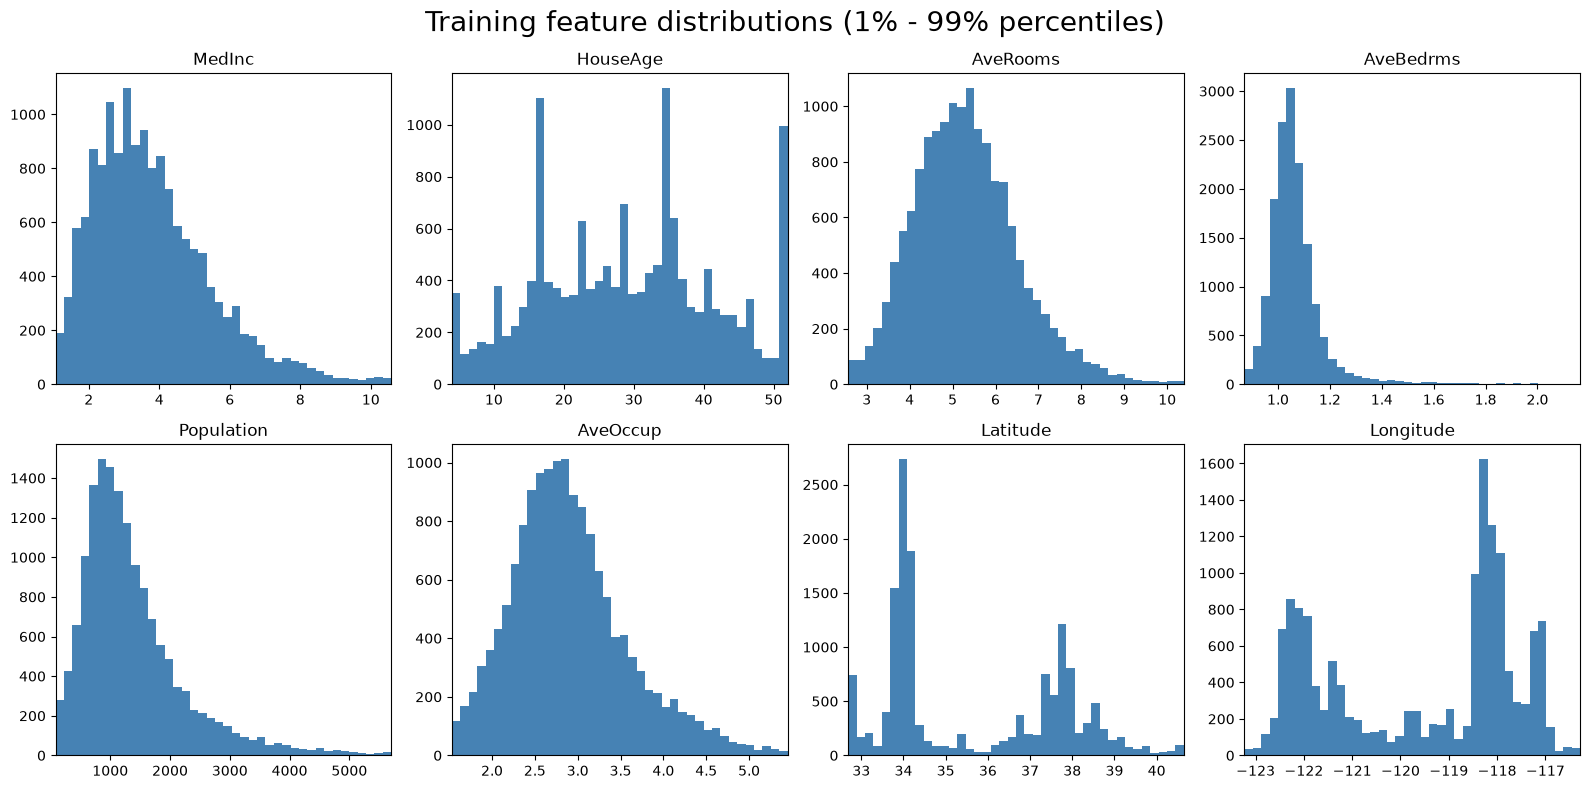

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000,15480.000000
mean,3.867932,28.634044,5.431607,1.095960,1421.528811,3.112156,35.634422,-119.569263
std,1.899344,12.642321,2.388734,0.427406,1124.197972,11.959223,2.138867,2.004747
min,0.499900,1.000000,0.846154,0.375000,3.000000,0.692308,32.560000,-124.350000
25%,2.565800,18.000000,4.443769,1.006118,787.000000,2.431797,33.930000,-121.790000
50%,3.528800,29.000000,5.230702,1.048833,1163.000000,2.823972,34.250000,-118.490000
75%,4.744150,37.000000,6.060497,1.099431,1719.250000,3.282093,37.720000,-118.000000
max,15.000100,52.000000,141.909091,25.636364,35682.000000,1243.333333,41.950000,-114.470000


In [105]:
# features
def analyse_features(X_set, color="steelblue", lower_pc=0, upper_pc=1):
    frame = pd.DataFrame(X_set, columns=FEATURE_NAMES)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))

    for ax, feature in zip(axes.flat, frame.columns):
        values = frame[feature]

        #ax.hist(values, bins=40)
        lower, upper = values.quantile([lower_pc, upper_pc])
        ax.hist(values, bins=40, range=(lower, upper),color=color)
        ax.set_xlim(lower, upper)

        ax.set_title(feature)

    if lower_pc != 0 and upper_pc != 1:
        plt.suptitle(f"Training feature distributions ({lower_pc:.0%} - {upper_pc:.0%} percentiles)",fontsize=20)
    else:
        plt.suptitle("Training feature distributions",fontsize=20)
    plt.tight_layout()
    plt.show()
    return frame.describe()

analyse_features(X_train,color="indianred")
analyse_features(X_train,lower_pc=0.01,upper_pc=0.99)   # 1-99% percentile

## 4. Make a regression training/validation split

The validation data is used to compare candidate models, 20% of the training data is held back for validation in this case.\
The subsets are then normalized with the `StandardScaler`. Fit the scaler on the SUBTRAINING data only, then use that fitted scaler to transform validation inputs. This avoids leaking information from validation into preprocessing.


In [106]:
X_subtrain, X_valid, y_subtrain, y_valid = train_test_split(
    X_train, y_train, test_size=0.2, random_state=SEED
)

# Fit preprocessing on the (sub)training data only.
scaler = StandardScaler()
X_subtrain_scaled = scaler.fit_transform(X_subtrain)
X_valid_scaled = scaler.transform(X_valid)
print(f"Subtraining: {X_subtrain_scaled.shape}; validation: {X_valid_scaled.shape}")

Subtraining: (12384, 8); validation: (3096, 8)


## 5. Defining the network and dataloader implementation

The network has fully connected `Linear` layers and `ReLU` activations. For regression, its output is one unrestricted value because the target is continuous (house value).\
A `DataLoader` supplies mini-batches. 

In [107]:
# Defining the network
class FeedForwardNetwork(nn.Module):
    def __init__(self, hidden_units, output_units=1):
        super().__init__()
        layers = []
        input_units = len(FEATURE_NAMES)                                    # e.g. 8 features = 8 input neurons
        for units in hidden_units:                                          # tupels e.g. (8,8,8) = 3 hidden layers with 8 hidden units
            layers.extend([nn.Linear(input_units, units),nn.ReLU()])        # layer + ReLU nonLin
            input_units = units
        layers.append(nn.Linear(input_units, output_units))                 # output layer = 1 outpur neuron (1 target val regression)
        self.network = nn.Sequential(*layers)                               # unpack layer list and feed the network (sequential)

    def forward(self, x):
        return self.network(x)

In [108]:
def predict(model, X):
    model.eval()
    x_tensor = torch.as_tensor(X, dtype=torch.float32, device=DEVICE)
    with torch.no_grad():
        return model(x_tensor).cpu().numpy()        # numpy only works on CPU TENSORS!

In [109]:
# Dataloader
def make_loader(X, y, batch_size, shuffle):
    x_tensor = torch.as_tensor(X, dtype=torch.float32)
    y_tensor = torch.as_tensor(y, dtype=torch.float32).reshape(-1, 1)
    dataset = TensorDataset(x_tensor, y_tensor)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle)

## 6. Implement the training algorithm
Train the model (minimizing the training loss) using SGD with mini batches.\
Consider case (a) for training/validation, (b) test set (validation set = None!)

In [110]:
def train_model(
        model,
        train_loader,
        valid_loader,
        *,
        epochs,
        learning_rate,
        loss_fn,
        progress_label="Training...",
    ):
    # Optimizer = SGD
    optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

    # record training (and validation) losses for analysis
    history = {"train_loss": []}
    if valid_loader is not None:
        history["val_loss"] = []

    # print(model)
    print(f"{progress_label} started ({epochs} epochs).", flush=True)

    # TRAINING
    for epoch in range(epochs):
        model.train()
        train_total = 0.0
        train_count = 0
        for data, targets in train_loader:
            data, targets = data.to(DEVICE), targets.to(DEVICE) # torch loading

            optimizer.zero_grad()                               # reset grads
            predictions = model(data)                           # forward
            loss = loss_fn(predictions, targets)                # calc loss
            loss.backward()                                     # backwards propagation
            optimizer.step()                                    # step

            train_total += loss.item() * len(data)              # ...as loss default returns "mean" over batch!
            train_count += len(data)                            # n per batch
        history["train_loss"].append(train_total / train_count) # avg over all batches!

        # VALIDATION (analogue to TRAINING)
        if valid_loader is not None:
            model.eval()
            val_total = 0.0
            val_count = 0
            with torch.no_grad():
                for data, targets in valid_loader:
                    data, targets = data.to(DEVICE), targets.to(DEVICE)
                    
                    predictions = model(data)
                    loss = loss_fn(predictions, targets)
                    val_total += loss.item() * len(data)
                    val_count += len(data)
            history["val_loss"].append(val_total / val_count)

        # Track some progress to see if the code is still running ...
        if (epoch + 1) % 10 == 0 or epoch == 0 or epoch + 1 == epochs:
            message = (
                f"{progress_label} | epoch {epoch + 1}/{epochs} | "
                f"train loss: {history['train_loss'][-1]:.4f}"
            )
            if valid_loader is not None:
                message += f" | validation loss: {history['val_loss'][-1]:.4f}"
            print(message, flush=True)

    return model, history

## 7. Define model configurations
At least 10 diffenrent configurations by varying numbers of hidden units and hidden layers should be tested.\
3 different numbers for hidden layers and 4 variations of hidden units per layer were tested -> 3x4 = 12 configurations

In [111]:
# configurations
configurations = []
learning_rate = 0.01
epochs = 150
batch_size = 64
config_idx = 1

# 12 configurations with N hidden layers x M hidden units {2^(N,M)}
for var_units in range(4,7):            # 2^4 to 2^6 = 16,32,64
    for var_layers in range(1,5):       # 2*1 to 2*4 = 2,4,6,8
        config_description =f"Config_{config_idx:02}: {2*var_layers} x {2**var_units}"        
        hidden_units = (2**var_units,)*(2*var_layers)     # make tuples for iterator (N=len, M=val)
        
        configurations.append({
            "config_description": config_description,
            "hidden_units": hidden_units,
            "learning_rate": learning_rate,
            "epochs": epochs,
            "batch_size": batch_size,
        })
        
        config_idx += 1

print("Configs defined by N hidden layers x M hidden units in the layer")
for config in configurations:
    print(f"{config["config_description"]} --> hidden_units = {config["hidden_units"]}")
        


Configs defined by N hidden layers x M hidden units in the layer
Config_01: 2 x 16 --> hidden_units = (16, 16)
Config_02: 4 x 16 --> hidden_units = (16, 16, 16, 16)
Config_03: 6 x 16 --> hidden_units = (16, 16, 16, 16, 16, 16)
Config_04: 8 x 16 --> hidden_units = (16, 16, 16, 16, 16, 16, 16, 16)
Config_05: 2 x 32 --> hidden_units = (32, 32)
Config_06: 4 x 32 --> hidden_units = (32, 32, 32, 32)
Config_07: 6 x 32 --> hidden_units = (32, 32, 32, 32, 32, 32)
Config_08: 8 x 32 --> hidden_units = (32, 32, 32, 32, 32, 32, 32, 32)
Config_09: 2 x 64 --> hidden_units = (64, 64)
Config_10: 4 x 64 --> hidden_units = (64, 64, 64, 64)
Config_11: 6 x 64 --> hidden_units = (64, 64, 64, 64, 64, 64)
Config_12: 8 x 64 --> hidden_units = (64, 64, 64, 64, 64, 64, 64, 64)


## 8. Run training algo and save the best performing regression model config

In [112]:
# Init
from copy import deepcopy
results = []
best_config = None
best_val_loss = float("inf")
best_history = None

# over all 12 configs
for config in configurations:
    progress_label = config["config_description"]
    print(f"Starting {progress_label} ... {config["epochs"]} epochs, batch_size={config["batch_size"]}, lr={config["learning_rate"]}", flush=True)
    
    # Training set
    train_loader = make_loader(
        X_subtrain_scaled, y_subtrain, config["batch_size"], shuffle=True
    )
    # Validation set
    val_loader = make_loader(
        X_valid_scaled, y_valid, config["batch_size"], shuffle=True
    )
    # Construct model
    model = FeedForwardNetwork(config["hidden_units"]).to(DEVICE)
    # Train model (and validate)
    model, history = train_model(
        model,
        train_loader,
        val_loader,
        epochs=config["epochs"],
        learning_rate=config["learning_rate"],
        loss_fn=nn.MSELoss(),
        progress_label=progress_label,
    )
    # last entries... most recent one
    train_loss = history["train_loss"][-1]
    val_loss = history["val_loss"][-1]
    print(
        f"Finished {progress_label} | train loss: {train_loss:.4f} | "
        f"validation loss: {val_loss:.4f}",
        flush=True,
    )
    print("=" * 78, flush=True)

    # save results to pick the best performing model
    result = config.copy()
    result["train_loss"] = train_loss
    result["val_loss"] = val_loss
    results.append(result)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_config = config.copy()
        best_history = deepcopy(history)    # create an independent copy of the history for report

Starting Config_01: 2 x 16 ... 150 epochs, batch_size=64, lr=0.01
Config_01: 2 x 16 started (150 epochs).
Config_01: 2 x 16 | epoch 1/150 | train loss: 1.0603 | validation loss: 0.7015
Config_01: 2 x 16 | epoch 10/150 | train loss: 0.4285 | validation loss: 0.4742
Config_01: 2 x 16 | epoch 20/150 | train loss: 0.3782 | validation loss: 0.4070
Config_01: 2 x 16 | epoch 30/150 | train loss: 0.3551 | validation loss: 0.3782
Config_01: 2 x 16 | epoch 40/150 | train loss: 0.3446 | validation loss: 0.3694
Config_01: 2 x 16 | epoch 50/150 | train loss: 0.3343 | validation loss: 0.3544
Config_01: 2 x 16 | epoch 60/150 | train loss: 0.3262 | validation loss: 0.3477
Config_01: 2 x 16 | epoch 70/150 | train loss: 0.3224 | validation loss: 0.3476
Config_01: 2 x 16 | epoch 80/150 | train loss: 0.3122 | validation loss: 0.3354
Config_01: 2 x 16 | epoch 90/150 | train loss: 0.3072 | validation loss: 0.3277
Config_01: 2 x 16 | epoch 100/150 | train loss: 0.3040 | validation loss: 0.3333
Config_01: 2 x

For report: table of config and results, sorted by best to worst

In [113]:
results_frame = pd.DataFrame(results).sort_values("val_loss")
display(results_frame)
print("Selected (final) configuration:", best_config)

,config_description,hidden_units,learning_rate,epochs,batch_size,train_loss,val_loss
9,Config_10: 4 x 64,"(64, 64, 64, 64)",0.01,150,64,0.235329,0.283512
8,Config_09: 2 x 64,"(64, 64)",0.01,150,64,0.255937,0.290951
6,Config_07: 6 x 32,"(32, 32, 32, 32, 32, 32)",0.01,150,64,0.255743,0.295951
5,Config_06: 4 x 32,"(32, 32, 32, 32)",0.01,150,64,0.246808,0.296895
4,Config_05: 2 x 32,"(32, 32)",0.01,150,64,0.272725,0.298276
11,Config_12: 8 x 64,"(64, 64, 64, 64, 64, 64, 64, 64)",0.01,150,64,0.240402,0.299140
10,Config_11: 6 x 64,"(64, 64, 64, 64, 64, 64)",0.01,150,64,0.238677,0.300122
2,Config_03: 6 x 16,"(16, 16, 16, 16, 16, 16)",0.01,150,64,0.282446,0.308734
1,Config_02: 4 x 16,"(16, 16, 16, 16)",0.01,150,64,0.266945,0.309485
7,Config_08: 8 x 32,"(32, 32, 32, 32, 32, 32, 32, 32)",0.01,150,64,0.251190,0.311017


Selected (final) configuration: {'config_description': 'Config_10: 4 x 64', 'hidden_units': (64, 64, 64, 64), 'learning_rate': 0.01, 'epochs': 150, 'batch_size': 64}


## 9. Best performing hyperparameter set
Model with best(lowest) validation loss --> best hyperparameter configuration

In [114]:
import pprint
print(f"Model selection, best result (validation loss = {best_val_loss:.04f}) \n... best config:")
pprint.pprint(best_config, sort_dicts=False)
model = FeedForwardNetwork(best_config["hidden_units"]).to(DEVICE)
print(f"\n NeuralNetwork Layer Structure:\n {model}")

Model selection, best result (validation loss = 0.2835) 
... best config:
{'config_description': 'Config_10: 4 x 64',
 'hidden_units': (64, 64, 64, 64),
 'learning_rate': 0.01,
 'epochs': 150,
 'batch_size': 64}

 NeuralNetwork Layer Structure:
 FeedForwardNetwork(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): ReLU()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): ReLU()
    (8): Linear(in_features=64, out_features=1, bias=True)
  )
)


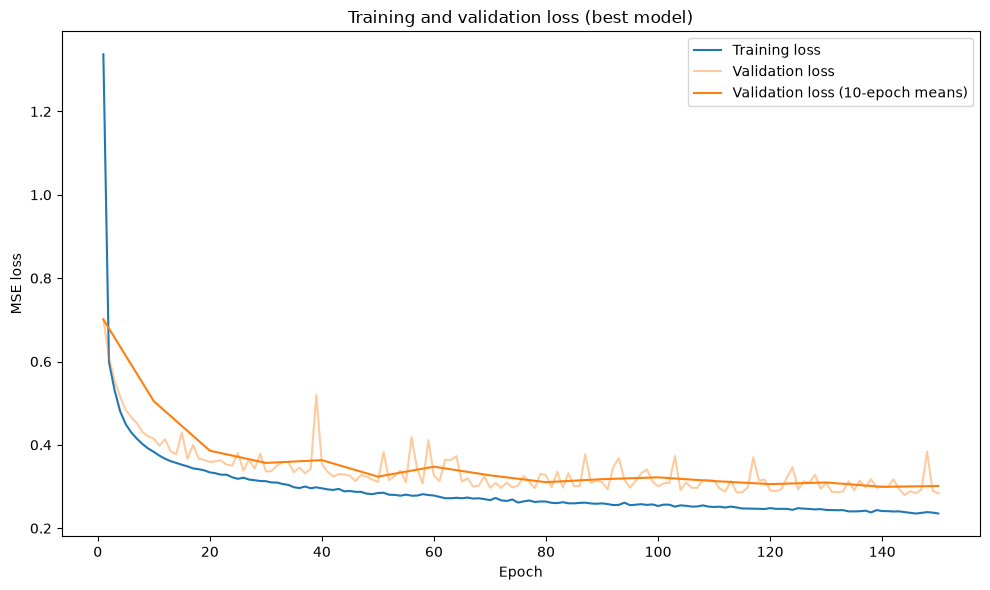

In [115]:
train_losses = np.array(best_history["train_loss"])
val_losses = np.array(best_history["val_loss"])

smooth_epochs = 10
val_losses_smoothed = np.concatenate(([val_losses[0]], val_losses.reshape(-1, smooth_epochs).mean(axis=1)))
epochs = np.arange(1, len(train_losses) + 1)
smoothed_epochs = np.concatenate(([epochs[0]], epochs[smooth_epochs - 1::smooth_epochs]))

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_losses, color="tab:blue", label="Training loss")
plt.plot(epochs, val_losses, color="tab:orange", alpha=0.4, label="Validation loss")
plt.plot(smoothed_epochs, val_losses_smoothed, color="tab:orange", label=f"Validation loss ({smooth_epochs}-epoch means)")
plt.title("Training and validation loss (best model)")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Final regression model
The best hyperparameter configuration was found in (9), use this config to train the model with the original training set (train+valid combined) and report the final test loss and plot the model predictions vs. ground truth

In [120]:
# Fit preprocessing on the training data only.
final_scaler = StandardScaler()
X_train_scaled = final_scaler.fit_transform(X_train)
X_test_scaled = final_scaler.transform(X_test)

# stop early to prevent overfitting
#best_config["epochs"] = 90

final_loader = make_loader(
    X_train_scaled, y_train, best_config["batch_size"], shuffle=True
)
final_model = FeedForwardNetwork(best_config["hidden_units"]).to(DEVICE)
final_model, final_history = train_model(
    final_model,
    final_loader,
    None,
    epochs=best_config["epochs"],
    learning_rate=best_config["learning_rate"],
    loss_fn=nn.MSELoss(),
)
print("Final regression model:")
print(final_model)
print(f"Final training loss: {final_history['train_loss'][-1]:.4f}")

y_pred = predict(final_model, X_test_scaled).reshape(-1)
test_mse = mean_squared_error(y_test, y_pred)
print(f"Final test MSE: {test_mse:.4f}")

Training... started (90 epochs).
Training... | epoch 1/90 | train loss: 1.1789
Training... | epoch 10/90 | train loss: 0.3702
Training... | epoch 20/90 | train loss: 0.3212
Training... | epoch 30/90 | train loss: 0.2994


KeyboardInterrupt: 

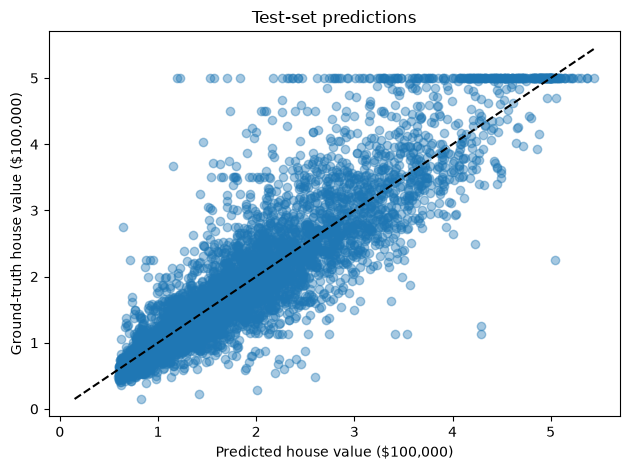

In [117]:
plt.scatter(y_pred, y_test, alpha=0.4)
limits = [min(float(y_pred.min()), float(y_test.min())),
          max(float(y_pred.max()), float(y_test.max()))]
plt.plot(limits, limits, "--", color="black")
plt.xlabel("Predicted house value ($100,000)")
plt.ylabel("Ground-truth house value ($100,000)")
plt.title("Test-set predictions")
plt.tight_layout()
plt.show()

## 11. Binary classification
Now we use the same config for a binary classification problem, where label=1 for houses with value > $200k ("high-priced"). Explain differences vs. regression task and report accuracy.

In [118]:
from sklearn.metrics import confusion_matrix

y_train_class = y_train.copy()      # dont transform original train set -> copy
y_test_class = y_test.copy()        # dont transform original test set -> copy

y_train_class[y_train_class < 2], y_test_class[y_test_class < 2] = 0, 0
y_train_class[y_train_class >= 2], y_test_class[y_test_class >= 2] = 1, 1

print("Training class distribition (0=below cutoff, 1=at/above cutoff):")
print(f"Class 0: {np.mean(y_train_class == 0):.2%}")
print(f"Class 1: {np.mean(y_train_class == 1):.2%}")
print("Test class distribution:")
print(f"Class 0: {np.mean(y_test_class == 0):.2%}")
print(f"Class 1: {np.mean(y_test_class == 1):.2%}")

# Fit preprocessing on the training data only.
classification_scaler = StandardScaler()
X_train_class_scaled = classification_scaler.fit_transform(X_train)
X_test_class_scaled = classification_scaler.transform(X_test)

classification_loader = make_loader(
    X_train_class_scaled,
    y_train_class,
    best_config["batch_size"],
    shuffle=True,
)
classifier = FeedForwardNetwork(best_config["hidden_units"], output_units=1).to(DEVICE)
classification_loss = nn.BCEWithLogitsLoss()
classifier, _ = train_model(
    classifier,
    classification_loader,
    None,
    epochs=best_config["epochs"],
    learning_rate=best_config["learning_rate"],
    loss_fn=classification_loss,
)

logits = predict(classifier, X_test_class_scaled).reshape(-1)
# Clip logits before the NumPy sigmoid to avoid overflow for extreme values.
probabilities = 1.0 / (1.0 + np.exp(-np.clip(logits, -200, 200)))
y_pred_binary = (probabilities >= 0.5)

# Calculate accurcy rate (correct classificaition) for predictions vs test set
true_labels = np.asarray(y_test_class).reshape(-1)
predictions = np.asarray(y_pred_binary).reshape(-1)
accuracy = np.mean(true_labels == predictions)

print(f"Accuracy (correct classificaition) rate: {accuracy:.2%}")
print("Confusion matrix:\n", confusion_matrix(y_test_class, y_pred_binary))

Training class distribition (0=below cutoff, 1=at/above cutoff):
Class 0: 57.71%
Class 1: 42.29%
Test class distribution:
Class 0: 57.21%
Class 1: 42.79%
Training... started (90 epochs).
Training... | epoch 1/90 | train loss: 0.6855
Training... | epoch 10/90 | train loss: 0.4227
Training... | epoch 20/90 | train loss: 0.3550
Training... | epoch 30/90 | train loss: 0.3348
Training... | epoch 40/90 | train loss: 0.3157
Training... | epoch 50/90 | train loss: 0.3020
Training... | epoch 60/90 | train loss: 0.2962
Training... | epoch 70/90 | train loss: 0.2917
Training... | epoch 80/90 | train loss: 0.2876
Training... | epoch 90/90 | train loss: 0.2839
Accuracy (correct classificaition) rate: 86.32%
Confusion matrix:
 [[2539  413]
 [ 293 1915]]
